# Lab 1 — Multiclass Classification

Maintenance preprocessing, an unresampled MLP, and a training-only oversampling comparison executed in Kaggle. Tuning and final test evaluation remain pending.

## 1. Multiclass target and dataset source

Predict `Failure Type` (six classes) from the Kaggle predictive-maintenance CSV. The binary `Target` column is excluded from inputs.

In [2]:
%pip install -q skorch imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


## 2. Environment, seeds, and device

Record package versions and device; seed Python, NumPy, and PyTorch with 42.

In [3]:
import random
import platform
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Python:", platform.python_version())
print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

for package in [
    "torch", "scikit-learn", "skorch", "pandas",
    "numpy", "matplotlib", "seaborn", "imbalanced-learn"
]:
    print(f"{package}: {version(package)}")

Python: 3.13.15
Device: cuda
GPU: Tesla T4
torch: 2.11.0+cu128
scikit-learn: 1.6.1
skorch: 1.4.0
pandas: 2.3.3
numpy: 2.1.3
matplotlib: 3.10.0
seaborn: 0.13.2
imbalanced-learn: 0.14.2


## 3. Load data, inspect schema, and exclude leaking columns

Exclude UDI, Product ID, and binary Target. Retain supplied failure-type labels, documenting 27 disagreements with the binary label.

In [4]:
DATA_PATH = Path(
    "/kaggle/input/datasets/shivamb/"
    "machine-predictive-maintenance-classification/"
    "predictive_maintenance.csv"
)

assert DATA_PATH.is_file(), f"Dataset not found: {DATA_PATH}"

maintenance = pd.read_csv(DATA_PATH)

print("Shape:", maintenance.shape)
print("Columns:", maintenance.columns.tolist())
display(maintenance.head())

assert "Failure Type" in maintenance.columns, "Expected target column missing."
assert maintenance["Failure Type"].notna().all(), "Missing target labels."

print("\nMulticlass target distribution:")
print(maintenance["Failure Type"].value_counts(dropna=False))

Shape: (10000, 10)
Columns: ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure



Multiclass target distribution:
Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64


In [5]:
TARGET = "Failure Type"

NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

CATEGORICAL_FEATURES = ["Type"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
EXCLUDED_COLUMNS = ["UDI", "Product ID", "Target"]

required_columns = FEATURES + EXCLUDED_COLUMNS + [TARGET]
missing_columns = set(required_columns) - set(maintenance.columns)

assert not missing_columns, f"Missing columns: {missing_columns}"

print("DATASET SIZE")
print("Rows:", len(maintenance))
print("Columns:", maintenance.shape[1])

column_summary = pd.DataFrame({
    "dtype": maintenance.dtypes.astype(str),
    "missing_count": maintenance.isna().sum(),
    "unique_values": maintenance.nunique(),
})

display(column_summary)

print("DUPLICATE CHECKS")
print("Fully duplicated rows:", maintenance.duplicated().sum())
print("Repeated UDI values:", maintenance["UDI"].duplicated().sum())
print(
    "Repeated feature combinations:",
    maintenance.duplicated(subset=FEATURES).sum(),
)

print("\nNUMERIC VALIDITY")
print(
    "Rows containing non-finite numeric features:",
    (~np.isfinite(maintenance[NUMERIC_FEATURES]).all(axis=1)).sum(),
)

print("\nPRODUCT TYPES")
print(maintenance["Type"].value_counts(dropna=False))

print("\nTARGET CLASSES")
print(maintenance[TARGET].value_counts(dropna=False))

DATASET SIZE
Rows: 10000
Columns: 10


,dtype,missing_count,unique_values
UDI,int64,0,10000
Product ID,object,0,10000
Type,object,0,3
Air temperature [K],float64,0,93
Process temperature [K],float64,0,82
Rotational speed [rpm],int64,0,941
Torque [Nm],float64,0,577
Tool wear [min],int64,0,246
Target,int64,0,2
Failure Type,object,0,6


DUPLICATE CHECKS
Fully duplicated rows: 0
Repeated UDI values: 0
Repeated feature combinations: 0

NUMERIC VALIDITY
Rows containing non-finite numeric features: 0

PRODUCT TYPES
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

TARGET CLASSES
Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64


In [6]:
validity_checks = pd.Series({
    "Non-positive air temperature": (
        maintenance["Air temperature [K]"] <= 0
    ).sum(),
    "Non-positive process temperature": (
        maintenance["Process temperature [K]"] <= 0
    ).sum(),
    "Non-positive rotational speed": (
        maintenance["Rotational speed [rpm]"] <= 0
    ).sum(),
    "Negative torque": (
        maintenance["Torque [Nm]"] < 0
    ).sum(),
    "Negative tool wear": (
        maintenance["Tool wear [min]"] < 0
    ).sum(),
    "Unexpected product type": (
        ~maintenance["Type"].isin(["L", "M", "H"])
    ).sum(),
    "Unexpected binary target": (
        ~maintenance["Target"].isin([0, 1])
    ).sum(),
})

print("VALIDITY CHECKS")
display(validity_checks.to_frame("row_count"))

print("BINARY TARGET VS FAILURE TYPE")
display(pd.crosstab(
    maintenance["Failure Type"],
    maintenance["Target"],
    margins=True,
))

failure_from_type = maintenance[TARGET].ne("No Failure").astype(int)
label_disagreements = maintenance.loc[
    maintenance["Target"].ne(failure_from_type),
    ["UDI", "Target", TARGET],
]

print("Rows where the two labels disagree:", len(label_disagreements))
display(label_disagreements.head(20))

VALIDITY CHECKS


,row_count
Non-positive air temperature,0
Non-positive process temperature,0
Non-positive rotational speed,0
Negative torque,0
Negative tool wear,0
Unexpected product type,0
Unexpected binary target,0


BINARY TARGET VS FAILURE TYPE


Target,0,1,All
Failure Type,,,
Heat Dissipation Failure,0,112,112
No Failure,9643,9,9652
Overstrain Failure,0,78,78
Power Failure,0,95,95
Random Failures,18,0,18
Tool Wear Failure,0,45,45
All,9661,339,10000


Rows where the two labels disagree: 27


,UDI,Target,Failure Type
1221,1222,0,Random Failures
1302,1303,0,Random Failures
1437,1438,1,No Failure
1748,1749,0,Random Failures
2072,2073,0,Random Failures
2559,2560,0,Random Failures
2749,2750,1,No Failure
3065,3066,0,Random Failures
3452,3453,0,Random Failures
4044,4045,1,No Failure


## 4. Stratified splits and exploratory analysis

Use 6,000 training, 2,000 validation, and 2,000 test rows. Explore training features and retain the test set for final evaluation.

In [7]:
from sklearn.model_selection import train_test_split

classification_data = maintenance[FEATURES + [TARGET]].copy()

development, test = train_test_split(
    classification_data,
    test_size=0.20,
    stratify=classification_data[TARGET],
    random_state=SEED,
)

train, validation = train_test_split(
    development,
    test_size=0.25,
    stratify=development[TARGET],
    random_state=SEED,
)

assert set(train.index).isdisjoint(validation.index)
assert set(train.index).isdisjoint(test.index)
assert set(validation.index).isdisjoint(test.index)
assert len(train) + len(validation) + len(test) == len(maintenance)
assert not set(EXCLUDED_COLUMNS).intersection(FEATURES)

class_names = sorted(classification_data[TARGET].unique())

class_counts = pd.DataFrame({
    name: partition[TARGET].value_counts().reindex(
        class_names, fill_value=0
    )
    for name, partition in [
        ("train", train),
        ("validation", validation),
        ("test", test),
    ]
})

assert (class_counts > 0).all().all()

print("PARTITION SIZES")
print({
    "train": len(train),
    "validation": len(validation),
    "test": len(test),
})

print("\nCLASS COUNTS")
display(class_counts)

print("Smallest training class:", class_counts["train"].min())
print("PASS: disjoint partitions; all six classes present in each.")

RESULTS_DIR = Path("/kaggle/working/results")
PLOT_DIR = Path("/kaggle/working/plots")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

class_counts.to_csv(
    RESULTS_DIR / "maintenance_split_class_counts.csv"
)

split_assignments = pd.concat([
    pd.DataFrame({
        "UDI": maintenance.loc[partition.index, "UDI"].to_numpy(),
        "split": name,
    })
    for name, partition in [
        ("train", train),
        ("validation", validation),
        ("test", test),
    ]
])

split_assignments.to_csv(
    RESULTS_DIR / "maintenance_split_assignments.csv",
    index=False,
)

label_disagreements.to_csv(
    RESULTS_DIR / "maintenance_label_disagreements.csv",
    index=False,
)

PARTITION SIZES
{'train': 6000, 'validation': 2000, 'test': 2000}

CLASS COUNTS


,train,validation,test
Failure Type,,,
Heat Dissipation Failure,67,23,22
No Failure,5792,1930,1930
Overstrain Failure,46,16,16
Power Failure,57,19,19
Random Failures,11,3,4
Tool Wear Failure,27,9,9


Smallest training class: 11
PASS: disjoint partitions; all six classes present in each.


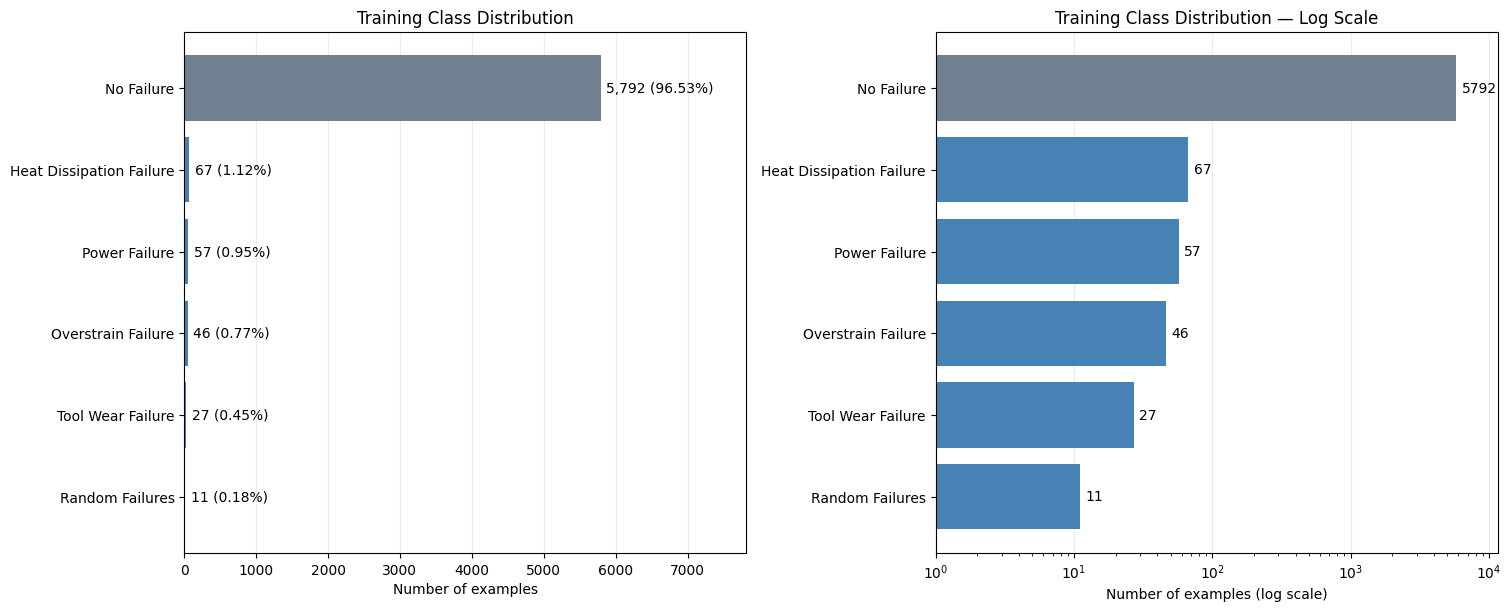

Largest-to-smallest training class ratio: 526.5


In [8]:
import matplotlib.pyplot as plt

training_counts = class_counts["train"].sort_values(ascending=False)
training_percentages = training_counts / len(train) * 100

fig, axes = plt.subplots(
    1, 2, figsize=(15, 6), constrained_layout=True
)

colors = [
    "slategray" if name == "No Failure" else "steelblue"
    for name in training_counts.index
]

for ax in axes:
    bars = ax.barh(
        training_counts.index,
        training_counts.values,
        color=colors,
    )
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

axes[0].bar_label(
    axes[0].containers[0],
    labels=[
        f"{count:,} ({percentage:.2f}%)"
        for count, percentage in zip(
            training_counts, training_percentages
        )
    ],
    padding=4,
)
axes[0].set_xlim(0, training_counts.max() * 1.35)
axes[0].set_title("Training Class Distribution")
axes[0].set_xlabel("Number of examples")

axes[1].set_xscale("log")
axes[1].set_xlim(1, training_counts.max() * 2)
axes[1].bar_label(axes[1].containers[0], padding=4)
axes[1].set_title("Training Class Distribution — Log Scale")
axes[1].set_xlabel("Number of examples (log scale)")

fig.savefig(
    PLOT_DIR / "maintenance_training_class_distribution.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print(
    "Largest-to-smallest training class ratio:",
    round(training_counts.max() / training_counts.min(), 1),
)

,count,mean,std,min,1%,25%,50%,75%,99%,max
Air temperature [K],6000.0,299.984,2.021,295.3,295.800,298.3,300.0,301.5,304.100,304.4
Process temperature [K],6000.0,309.993,1.490,305.7,306.500,308.8,310.1,311.1,313.300,313.8
Rotational speed [rpm],6000.0,1534.979,177.108,1168.0,1271.000,1421.0,1500.0,1609.0,2165.090,2833.0
Torque [Nm],6000.0,40.176,9.991,5.6,16.899,33.4,40.3,47.0,63.402,76.6
Tool wear [min],6000.0,107.910,63.391,0.0,0.000,54.0,108.0,162.0,223.000,246.0


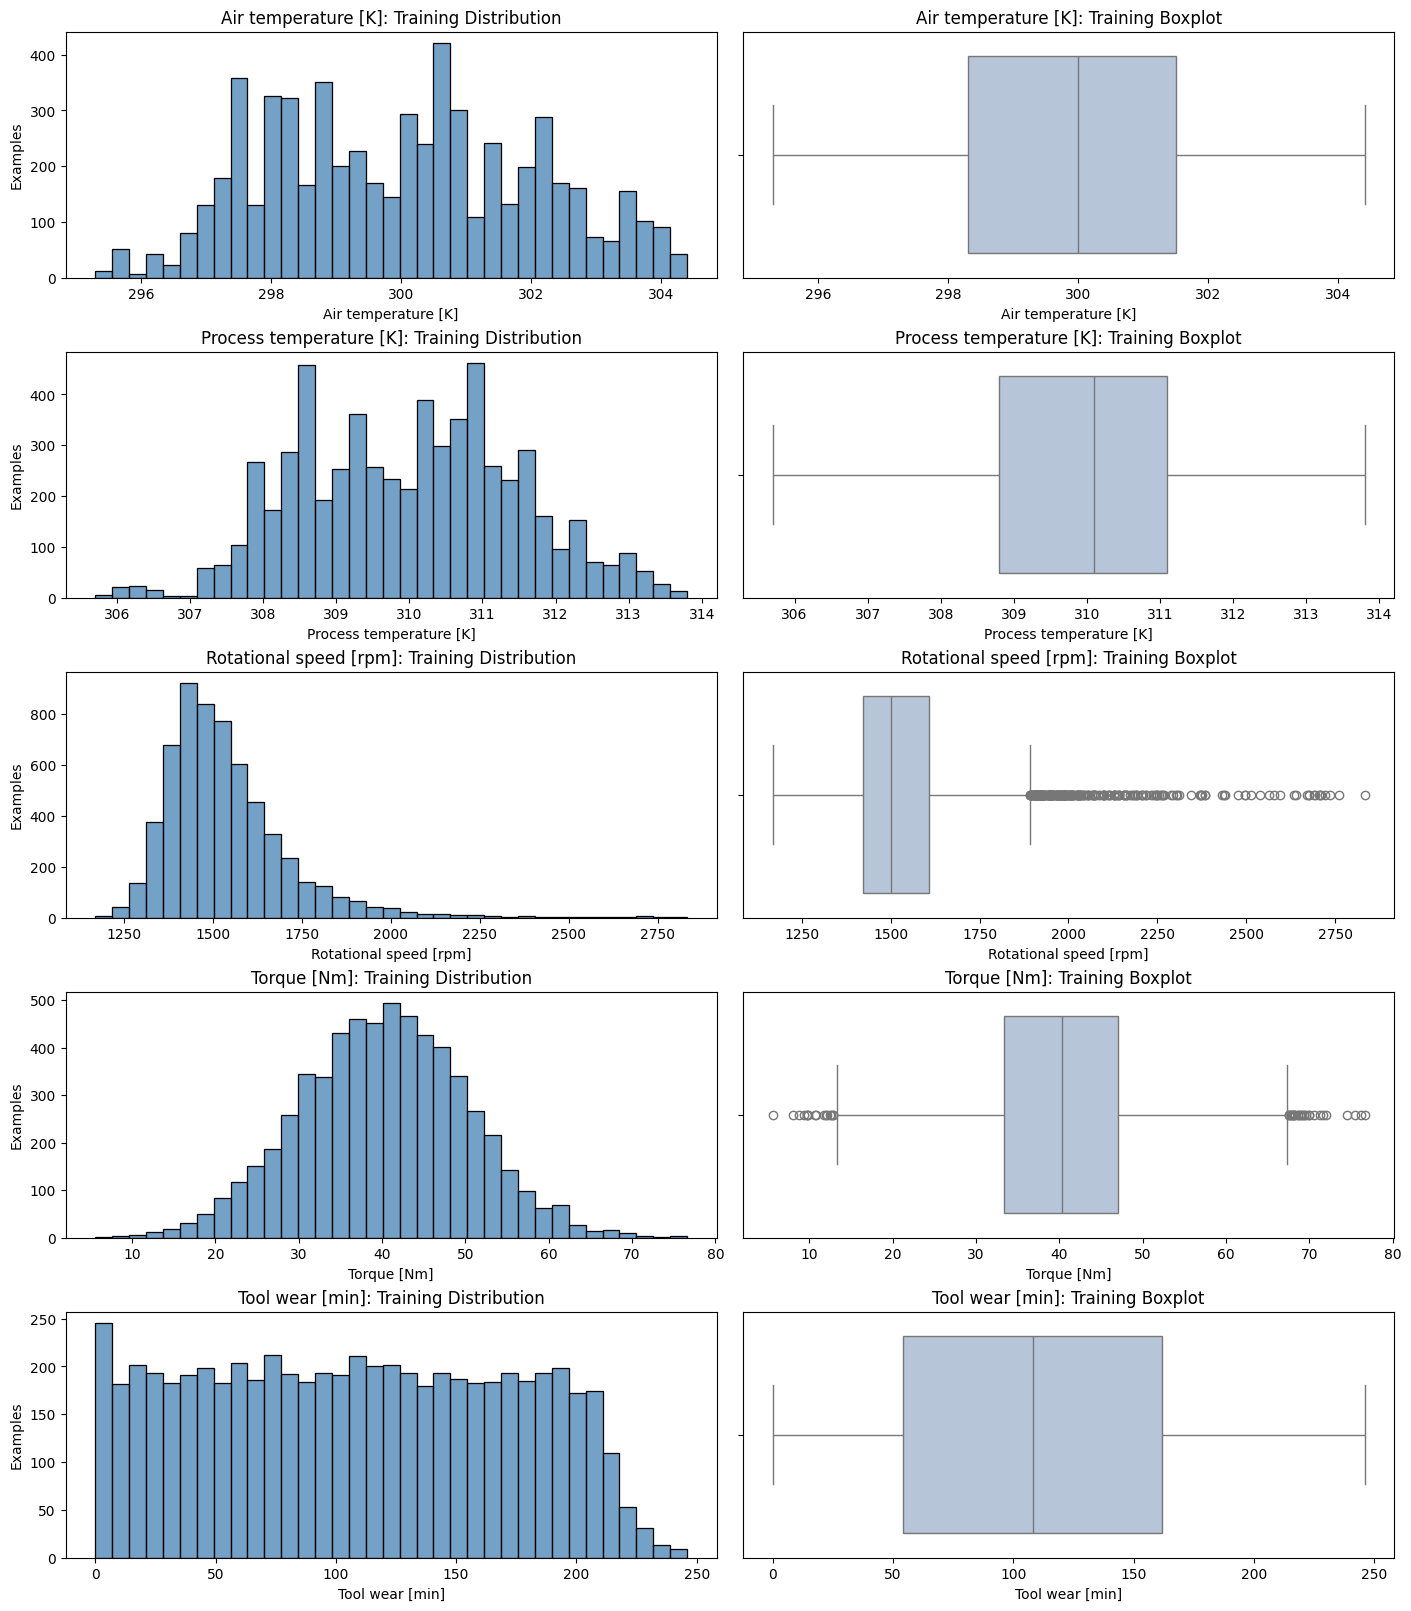

In [9]:
import seaborn as sns

numeric_summary = train[NUMERIC_FEATURES].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).T

display(numeric_summary.round(3))

numeric_summary.to_csv(
    RESULTS_DIR / "maintenance_training_numeric_summary.csv"
)

fig, axes = plt.subplots(
    len(NUMERIC_FEATURES),
    2,
    figsize=(14, 16),
    constrained_layout=True,
)

for row, feature in enumerate(NUMERIC_FEATURES):
    sns.histplot(
        data=train,
        x=feature,
        bins=35,
        color="steelblue",
        ax=axes[row, 0],
    )
    axes[row, 0].set_title(f"{feature}: Training Distribution")
    axes[row, 0].set_ylabel("Examples")

    sns.boxplot(
        data=train,
        x=feature,
        color="lightsteelblue",
        ax=axes[row, 1],
    )
    axes[row, 1].set_title(f"{feature}: Training Boxplot")

fig.savefig(
    PLOT_DIR / "maintenance_training_numeric_distributions.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

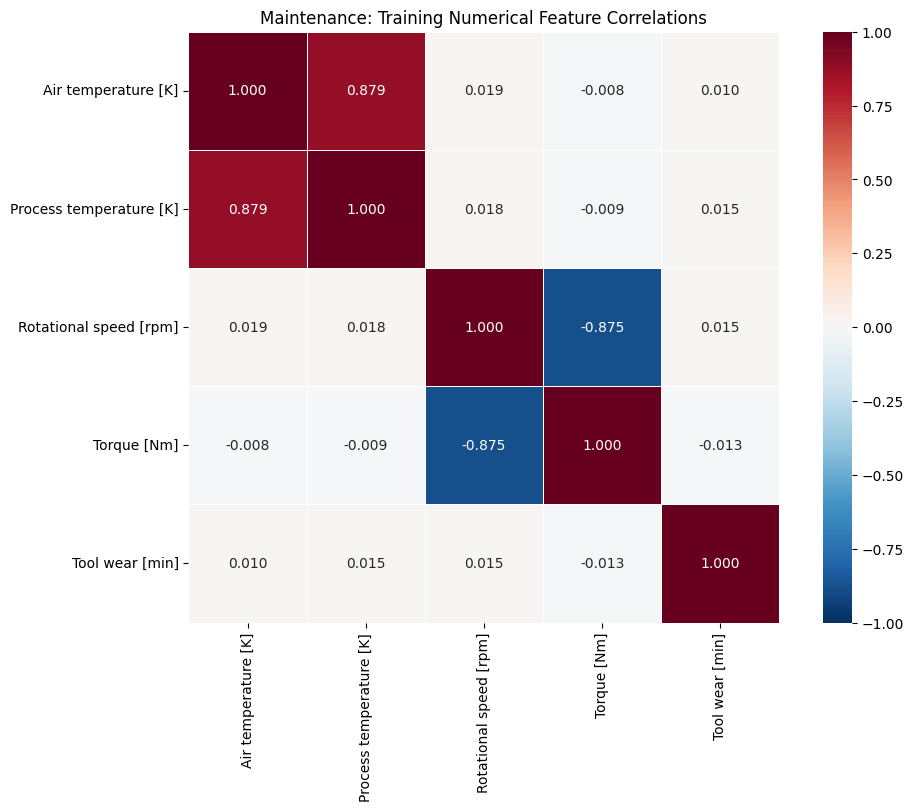

In [10]:
feature_correlations = train[NUMERIC_FEATURES].corr()

fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)

sns.heatmap(
    feature_correlations,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax,
)

ax.set_title("Maintenance: Training Numerical Feature Correlations")

fig.savefig(
    PLOT_DIR / "maintenance_training_correlations.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

feature_correlations.to_csv(
    RESULTS_DIR / "maintenance_training_correlations.csv"
)

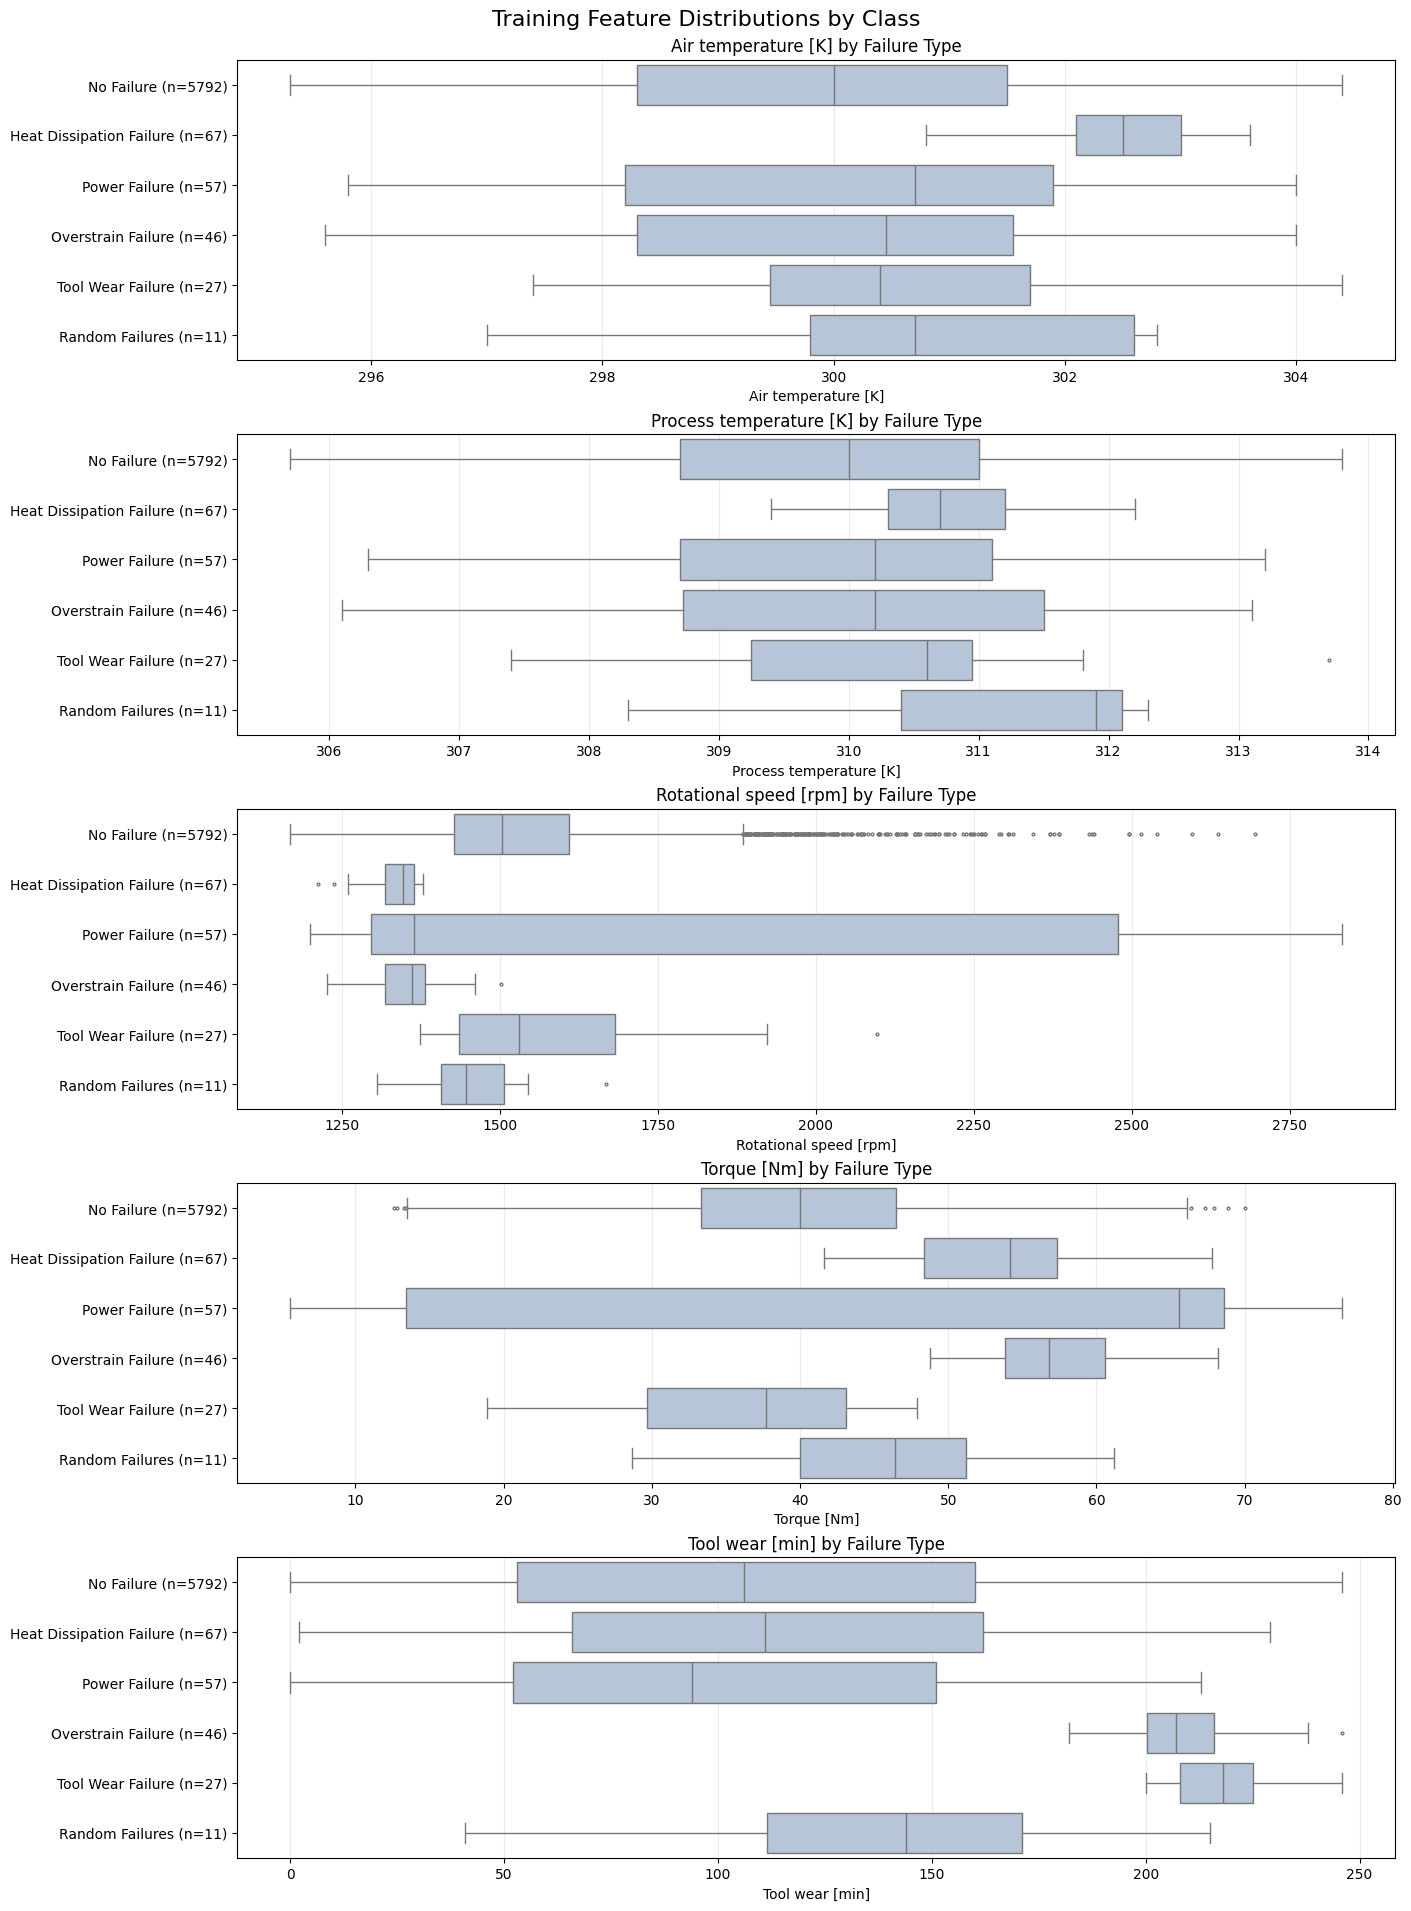

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Failure Type,,,,,
No Failure,300.00,310.0,1504.0,40.0,106.0
Heat Dissipation Failure,302.50,310.7,1346.0,54.2,111.0
Power Failure,300.70,310.2,1364.0,65.6,94.0
Overstrain Failure,300.45,310.2,1360.5,56.8,207.0
Tool Wear Failure,300.40,310.6,1530.0,37.7,218.0
Random Failures,300.70,311.9,1447.0,46.4,144.0


In [11]:
class_order = train[TARGET].value_counts().index.tolist()
class_labels = [
    f"{name} (n={int((train[TARGET] == name).sum())})"
    for name in class_order
]

fig, axes = plt.subplots(
    len(NUMERIC_FEATURES),
    1,
    figsize=(14, 19),
    constrained_layout=True,
)

for ax, feature in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(
        data=train,
        x=feature,
        y=TARGET,
        order=class_order,
        color="lightsteelblue",
        fliersize=2,
        ax=ax,
    )

    ax.set_yticks(range(len(class_order)))
    ax.set_yticklabels(class_labels)
    ax.set_ylabel("")
    ax.set_title(f"{feature} by Failure Type")
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "Training Feature Distributions by Class",
    fontsize=16,
)

fig.savefig(
    PLOT_DIR / "maintenance_training_features_by_class.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

class_medians = (
    train.groupby(TARGET)[NUMERIC_FEATURES]
    .median()
    .reindex(class_order)
)

display(class_medians.round(3))

class_medians.to_csv(
    RESULTS_DIR / "maintenance_training_class_medians.csv"
)

TRAINING CLASS COUNTS BY PRODUCT TYPE


Failure Type,No Failure,Heat Dissipation Failure,Power Failure,Overstrain Failure,Tool Wear Failure,Random Failures
Type,,,,,,
L,3473,43,34,41,15,9
M,1742,19,19,4,8,1
H,577,5,4,1,4,1


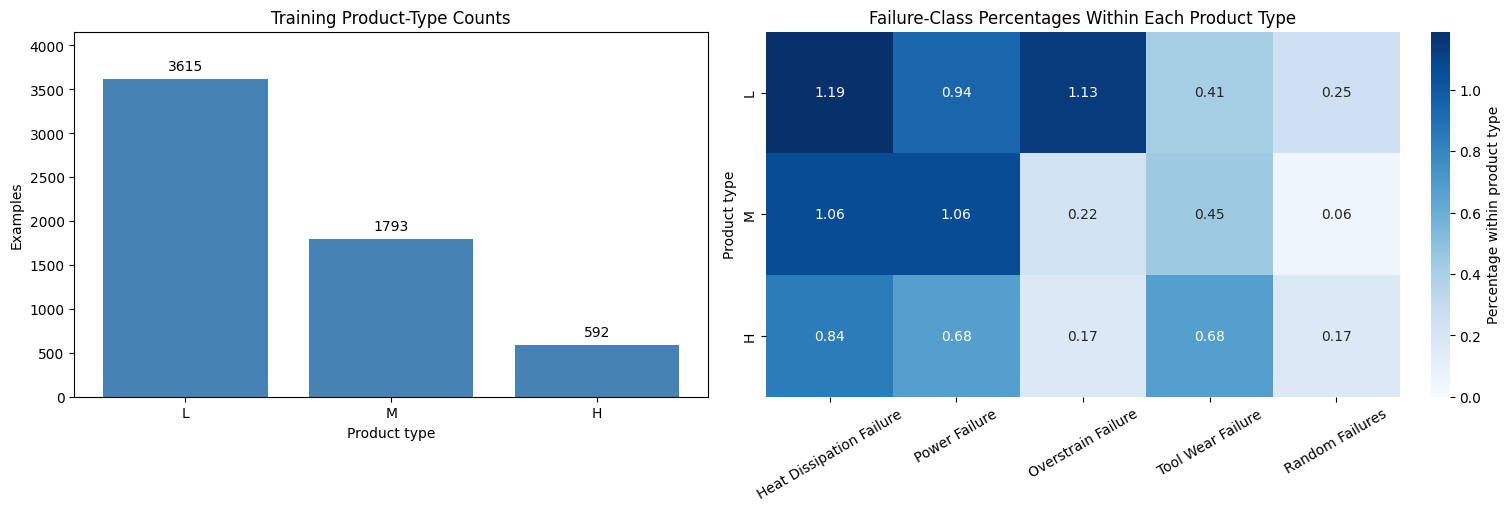

In [12]:
type_class_counts = pd.crosstab(
    train["Type"],
    train[TARGET],
).reindex(
    index=["L", "M", "H"],
    columns=class_order,
    fill_value=0,
)

type_class_percentages = (
    type_class_counts
    .div(type_class_counts.sum(axis=1), axis=0)
    .mul(100)
)

print("TRAINING CLASS COUNTS BY PRODUCT TYPE")
display(type_class_counts)

failure_columns = [
    name for name in class_order if name != "No Failure"
]

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5), constrained_layout=True
)

type_counts = type_class_counts.sum(axis=1)

bars = axes[0].bar(
    type_counts.index,
    type_counts.values,
    color="steelblue",
)
axes[0].bar_label(bars, padding=4)
axes[0].set_ylim(0, type_counts.max() * 1.15)
axes[0].set_title("Training Product-Type Counts")
axes[0].set_xlabel("Product type")
axes[0].set_ylabel("Examples")

sns.heatmap(
    type_class_percentages[failure_columns],
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    cbar_kws={"label": "Percentage within product type"},
    ax=axes[1],
)
axes[1].set_title("Failure-Class Percentages Within Each Product Type")
axes[1].set_xlabel("")
axes[1].set_ylabel("Product type")
axes[1].tick_params(axis="x", labelrotation=30)

fig.savefig(
    PLOT_DIR / "maintenance_training_product_types.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

type_class_counts.to_csv(
    RESULTS_DIR / "maintenance_training_type_class_counts.csv"
)
type_class_percentages.to_csv(
    RESULTS_DIR / "maintenance_training_type_class_percentages.csv"
)

## 5. Training-only preprocessing

Standardize five numerical features and one-hot encode product type using training data only, yielding eight inputs. Encode the six target classes as integer IDs.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), NUMERIC_FEATURES),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
                dtype=np.float32,
            ),
            CATEGORICAL_FEATURES,
        ),
    ],
    remainder="drop",
)

X_train = preprocessor.fit_transform(
    train[FEATURES]
).astype(np.float32)

X_val = preprocessor.transform(
    validation[FEATURES]
).astype(np.float32)

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(train[TARGET]).astype(np.int64)
y_val = label_encoder.transform(validation[TARGET]).astype(np.int64)

feature_names = preprocessor.get_feature_names_out()

label_mapping = pd.DataFrame({
    "class_id": np.arange(len(label_encoder.classes_)),
    "failure_type": label_encoder.classes_,
})

numeric_scaler = preprocessor.named_transformers_["numeric"]

assert int(numeric_scaler.n_samples_seen_) == len(train)
assert X_train.shape == (len(train), len(feature_names))
assert X_val.shape == (len(validation), len(feature_names))
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()

np.testing.assert_allclose(
    X_train[:, :len(NUMERIC_FEATURES)].mean(axis=0),
    0,
    atol=1e-6,
)
np.testing.assert_allclose(
    X_train[:, :len(NUMERIC_FEATURES)].std(axis=0),
    1,
    atol=1e-5,
)

print("ENCODED FEATURES")
print(feature_names.tolist())

print("\nTARGET LABEL MAPPING")
display(label_mapping)

print("Training shapes:", X_train.shape, y_train.shape)
print("Validation shapes:", X_val.shape, y_val.shape)
print("Input dtype:", X_train.dtype)
print("Target dtype:", y_train.dtype)
print("PASS: preprocessing fitted on training data only.")

label_mapping.to_csv(
    RESULTS_DIR / "maintenance_label_mapping.csv",
    index=False,
)

ENCODED FEATURES
['numeric__Air temperature [K]', 'numeric__Process temperature [K]', 'numeric__Rotational speed [rpm]', 'numeric__Torque [Nm]', 'numeric__Tool wear [min]', 'categorical__Type_H', 'categorical__Type_L', 'categorical__Type_M']

TARGET LABEL MAPPING


,class_id,failure_type
0,0,Heat Dissipation Failure
1,1,No Failure
2,2,Overstrain Failure
3,3,Power Failure
4,4,Random Failures
5,5,Tool Wear Failure


Training shapes: (6000, 8) (6000,)
Validation shapes: (2000, 8) (2000,)
Input dtype: float32
Target dtype: int64
PASS: preprocessing fitted on training data only.


In [14]:
import json
from sklearn.model_selection import StratifiedKFold

classification_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED,
)

cv_class_rows = []

for fold, (fit_indices, score_indices) in enumerate(
    classification_cv.split(train[FEATURES], y_train),
    start=1,
):
    assert set(fit_indices).isdisjoint(score_indices)

    for partition, indices in [
        ("fit", fit_indices),
        ("score", score_indices),
    ]:
        counts = np.bincount(
            y_train[indices],
            minlength=len(label_encoder.classes_),
        )

        assert (counts > 0).all()

        cv_class_rows.append({
            "fold": fold,
            "partition": partition,
            **dict(zip(label_encoder.classes_, counts.tolist())),
        })

cv_class_support = pd.DataFrame(cv_class_rows)
display(cv_class_support.set_index(["fold", "partition"]))

preprocessing_config = {
    "target": TARGET,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "excluded_columns": EXCLUDED_COLUMNS,
    "encoded_features": feature_names.tolist(),
    "label_mapping": {
        name: int(index)
        for index, name in enumerate(label_encoder.classes_)
    },
    "split": {
        "method": "Two-stage stratified random split",
        "seed": SEED,
        "train_samples": len(train),
        "validation_samples": len(validation),
        "test_samples": len(test),
    },
    "numeric_scaling": {
        "fit_partition": "Original training data",
        "mean": numeric_scaler.mean_.tolist(),
        "scale": numeric_scaler.scale_.tolist(),
    },
    "categorical_encoding": {
        "method": "OneHotEncoder",
        "categories": (
            preprocessor.named_transformers_["categorical"]
            .categories_[0].tolist()
        ),
        "handle_unknown": "ignore",
    },
    "cv": {
        "method": "StratifiedKFold",
        "n_splits": 3,
        "shuffle": True,
        "seed": SEED,
        "preprocessing": "Fit separately within each training fold",
        "resampling": "Training folds only, when enabled",
    },
    "label_disagreements": {
        "count": len(label_disagreements),
        "policy": "Keep supplied Failure Type labels and all rows",
    },
    "balancing_applied": False,
    "test_evaluated": False,
}

cv_class_support.to_csv(
    RESULTS_DIR / "maintenance_cv_class_support.csv",
    index=False,
)

(RESULTS_DIR / "maintenance_preprocessing_config.json").write_text(
    json.dumps(preprocessing_config, indent=2),
    encoding="utf-8",
)

print("PASS: all six classes occur in every CV fit and scoring partition.")
print("Saved CV class support and preprocessing configuration.")

Heat Dissipation Failure  No Failure  Overstrain Failure  \
fold partition                                                             
1    fit                              45        3861                  31   
     score                            22        1931                  15   
2    fit                              44        3861                  31   
     score                            23        1931                  15   
3    fit                              45        3862                  30   
     score                            22        1930                  16   

                Power Failure  Random Failures  Tool Wear Failure  
fold partition                                                     
1    fit                   38                7                 18  
     score                 19                4                  9  
2    fit                   38                8                 18  
     score                 19                3                  9  
3    fit                   38                7                 18  
     score                 19                4                  9

PASS: all six classes occur in every CV fit and scoring partition.
Saved CV class support and preprocessing configuration.


### Preprocessing and EDA conclusions

The maintenance dataset contains 10,000 rows and six failure-type
classes. No missing values, fully duplicated rows, repeated feature
combinations, or non-finite numerical values were found. Basic
physical-validity checks also passed.

Failure Type is the multiclass target. UDI and Product ID are excluded
as identifiers, and binary Target is excluded because it provides
outcome information.

There are 27 disagreements between binary Target and Failure Type:
18 Random Failures rows have Target = 0, and nine No Failure rows
have Target = 1. All rows and supplied Failure Type labels are retained;
the disagreement is documented rather than corrected without evidence.

### Partitions and imbalance

A stratified split with seed 42 produces 6,000 training, 2,000 validation,
and 2,000 test samples. All classes occur in every partition.
The split evaluates held-out records, not future-time forecasting.

No Failure accounts for 96.53% of training data. Random Failures has
only 11 training, three validation, and four test examples.
Accuracy alone is therefore insufficient; model comparisons will
prioritize macro-F1 and include per-class recall and F1.

Three-fold stratified CV retains every class in each partition.
However, Random Failures has only 3–4 examples per scoring fold,
so its estimated performance will be uncertain.

### Exploratory findings

- Air and process temperatures are positively correlated (r ≈ 0.879).
- Rotational speed and torque are negatively correlated (r ≈ −0.875).
- Rotational speed is right-skewed; extreme observations are retained.
- Heat Dissipation Failure has higher median air temperature and lower
  median rotational speed than No Failure.
- Overstrain Failure and Tool Wear Failure show higher tool wear.
- Product-type failure percentages differ, but some groups contain
  very few failure examples.

These are training-data associations, not causal conclusions.

### Preprocessing decisions

The five numerical features are standardized using training-only
statistics. Type is one-hot encoded, producing eight input features
in total. Failure Type is encoded as six integer class IDs.

Training inputs use float32 and targets use int64.
Validation uses the fitted training transformation unchanged.
During cross-validation, preprocessing will be fitted separately
within each training fold.

No balancing has been applied yet. The unbalanced baseline will be
compared with training-only oversampling. Validation and test class
distributions remain unchanged, and the test set remains unevaluated.

## 6. Unresampled baseline PyTorch MLP

Train an 8–32–16–6 ReLU MLP with unweighted cross-entropy, Adam (0.001), batch size 64, and 50 fixed epochs. Compare with the majority-class baseline. Validation macro-F1 is 0.500755, versus 0.163698 for the dummy; Random and Tool Wear failures have zero recall. The final epoch is retained.

In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
)

dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

dummy_rows = []

for split, X, y in [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
]:
    predictions = dummy_model.predict(X)

    dummy_rows.append({
        "model": "Majority-class baseline",
        "split": split,
        "accuracy": accuracy_score(y, predictions),
        "macro_recall": balanced_accuracy_score(y, predictions),
        "macro_f1": f1_score(
            y,
            predictions,
            labels=np.arange(len(label_encoder.classes_)),
            average="macro",
            zero_division=0,
        ),
    })

dummy_results = pd.DataFrame(dummy_rows)
display(dummy_results.round(6))

dummy_val_predictions = dummy_model.predict(X_val)

dummy_report = pd.DataFrame(
    classification_report(
        y_val,
        dummy_val_predictions,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        output_dict=True,
        zero_division=0,
    )
).T

print("VALIDATION CLASSIFICATION REPORT")
display(dummy_report.round(4))

dummy_results.to_csv(
    RESULTS_DIR / "maintenance_dummy_metrics.csv",
    index=False,
)
dummy_report.to_csv(
    RESULTS_DIR / "maintenance_dummy_validation_report.csv"
)

print("Training data remain unresampled.")
print("Test set remains unevaluated.")

,model,split,accuracy,macro_recall,macro_f1
0,Majority-class baseline,train,0.965333,0.166667,0.163727
1,Majority-class baseline,validation,0.965000,0.166667,0.163698


VALIDATION CLASSIFICATION REPORT


,precision,recall,f1-score,support
Heat Dissipation Failure,0.0000,0.0000,0.0000,23.000
No Failure,0.9650,1.0000,0.9822,1930.000
Overstrain Failure,0.0000,0.0000,0.0000,16.000
Power Failure,0.0000,0.0000,0.0000,19.000
Random Failures,0.0000,0.0000,0.0000,3.000
Tool Wear Failure,0.0000,0.0000,0.0000,9.000
accuracy,0.9650,0.9650,0.9650,0.965
macro avg,0.1608,0.1667,0.1637,2000.000
weighted avg,0.9312,0.9650,0.9478,2000.000


Training data remain unresampled.
Test set remains unevaluated.


In [18]:
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


class MaintenanceMLP(nn.Module):
    def __init__(self, input_dim=8, num_classes=6):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, num_classes),
        )

    def forward(self, x):
        return self.network(x)


BATCH_SIZE = 64
LEARNING_RATE = 0.001
EPOCHS = 50
NUM_CLASSES = len(label_encoder.classes_)

X_train_tensor = torch.from_numpy(X_train)
y_train_tensor = torch.from_numpy(y_train)
X_val_tensor = torch.from_numpy(X_val)
y_val_tensor = torch.from_numpy(y_val)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
)

classification_model = MaintenanceMLP(
    input_dim=X_train.shape[1],
    num_classes=NUM_CLASSES,
).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    classification_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.0,
)

classification_model.eval()

with torch.no_grad():
    sample_logits = classification_model(
        X_train_tensor[:8].to(DEVICE)
    )
    sample_loss = criterion(
        sample_logits,
        y_train_tensor[:8].to(DEVICE),
    )

assert sample_logits.shape == (8, NUM_CLASSES)
assert torch.isfinite(sample_logits).all()
assert torch.isfinite(sample_loss)
assert y_train_tensor.dtype == torch.int64

print(classification_model)
print("Trainable parameters:", sum(
    p.numel()
    for p in classification_model.parameters()
    if p.requires_grad
))
print("Batches per epoch:", len(train_loader))
print("Output shape:", sample_logits.shape)
print("Device:", next(classification_model.parameters()).device)
print("PASS: forward pass and cross-entropy loss.")

MaintenanceMLP(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=6, bias=True)
  )
)
Trainable parameters: 918
Batches per epoch: 94
Output shape: torch.Size([8, 6])
Device: cuda:0
PASS: forward pass and cross-entropy loss.


In [19]:
X_train_device = X_train_tensor.to(DEVICE)
y_train_device = y_train_tensor.to(DEVICE)
X_val_device = X_val_tensor.to(DEVICE)
y_val_device = y_val_tensor.to(DEVICE)

classification_history_rows = []

for epoch in range(1, EPOCHS + 1):
    classification_model.train()

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits = classification_model(X_batch)
        loss = criterion(logits, y_batch)

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite loss at epoch {epoch}")

        loss.backward()
        optimizer.step()

    classification_model.eval()
    row = {"epoch": epoch}

    with torch.no_grad():
        for split, X, y in [
            ("train", X_train_device, y_train_device),
            ("validation", X_val_device, y_val_device),
        ]:
            logits = classification_model(X)
            predictions = logits.argmax(dim=1).cpu().numpy()
            actual = y.cpu().numpy()

            row[f"{split}_loss"] = criterion(logits, y).item()
            row[f"{split}_accuracy"] = accuracy_score(
                actual, predictions
            )
            row[f"{split}_macro_f1"] = f1_score(
                actual,
                predictions,
                labels=np.arange(NUM_CLASSES),
                average="macro",
                zero_division=0,
            )
            row[f"{split}_macro_recall"] = balanced_accuracy_score(
                actual, predictions
            )

    classification_history_rows.append(row)

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:2d}/{EPOCHS} | "
            f"Loss: {row['train_loss']:.4f} / "
            f"{row['validation_loss']:.4f} | "
            f"Accuracy: {row['train_accuracy']:.4f} / "
            f"{row['validation_accuracy']:.4f} | "
            f"Macro-F1: {row['train_macro_f1']:.4f} / "
            f"{row['validation_macro_f1']:.4f}"
        )

classification_history = pd.DataFrame(classification_history_rows)

assert len(classification_history) == EPOCHS
assert np.isfinite(classification_history.to_numpy()).all()

classification_history.to_csv(
    RESULTS_DIR / "maintenance_baseline_training_history.csv",
    index=False,
)

print("\nPASS: training completed; history saved.")
print("Metric pairs are training / validation.")
print("Test set remains unevaluated.")

Epoch  1/50 | Loss: 0.6575 / 0.6686 | Accuracy: 0.9653 / 0.9650 | Macro-F1: 0.1637 / 0.1637
Epoch 10/50 | Loss: 0.1228 / 0.1239 | Accuracy: 0.9668 / 0.9660 | Macro-F1: 0.2147 / 0.1943
Epoch 20/50 | Loss: 0.0924 / 0.0956 | Accuracy: 0.9722 / 0.9680 | Macro-F1: 0.3306 / 0.3056
Epoch 30/50 | Loss: 0.0736 / 0.0789 | Accuracy: 0.9752 / 0.9750 | Macro-F1: 0.4273 / 0.4272
Epoch 40/50 | Loss: 0.0643 / 0.0726 | Accuracy: 0.9787 / 0.9765 | Macro-F1: 0.4892 / 0.4668
Epoch 50/50 | Loss: 0.0594 / 0.0675 | Accuracy: 0.9793 / 0.9800 | Macro-F1: 0.5038 / 0.5008

PASS: training completed; history saved.
Metric pairs are training / validation.
Test set remains unevaluated.


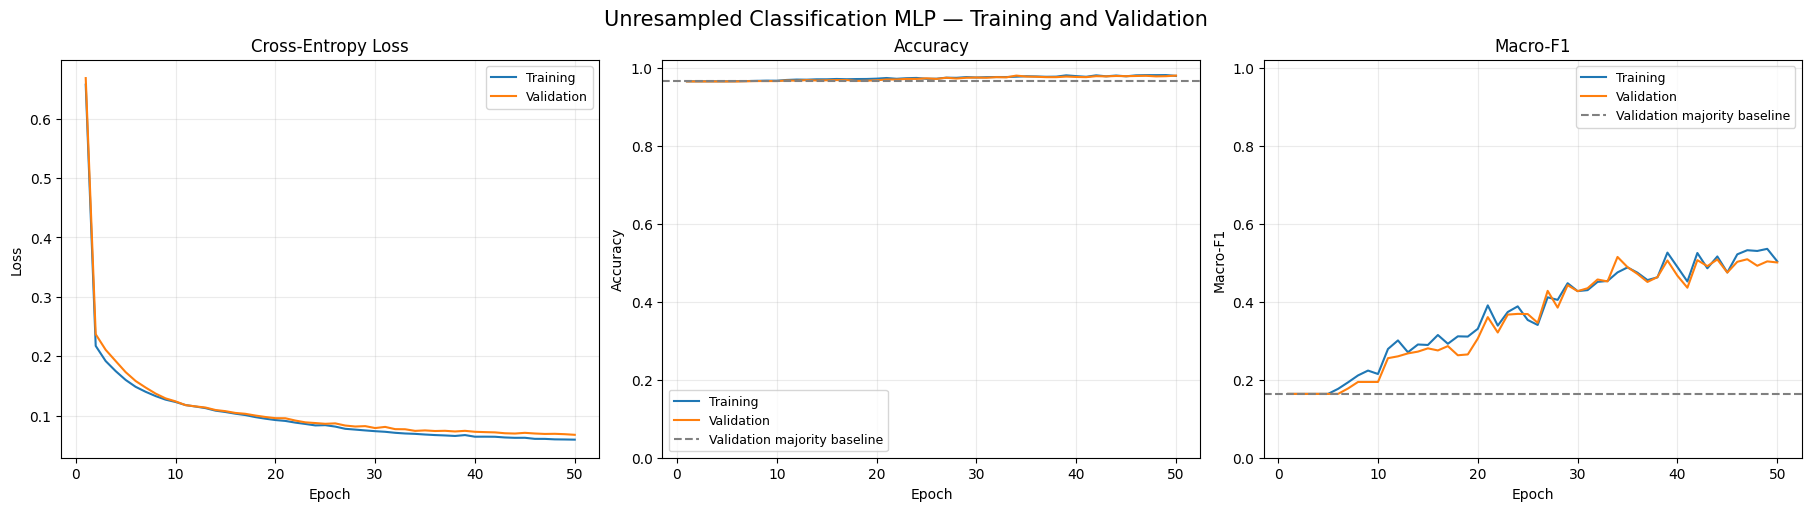

In [20]:
fig, axes = plt.subplots(
    1, 3, figsize=(18, 5), constrained_layout=True
)

plot_specs = [
    ("loss", "Cross-Entropy Loss", "Loss"),
    ("accuracy", "Accuracy", "Accuracy"),
    ("macro_f1", "Macro-F1", "Macro-F1"),
]

for ax, (metric, title, ylabel) in zip(axes, plot_specs):
    ax.plot(
        classification_history["epoch"],
        classification_history[f"train_{metric}"],
        label="Training",
    )
    ax.plot(
        classification_history["epoch"],
        classification_history[f"validation_{metric}"],
        label="Validation",
    )

    if metric in ["accuracy", "macro_f1"]:
        baseline_value = dummy_results.loc[
            dummy_results["split"].eq("validation"),
            metric,
        ].iloc[0]

        ax.axhline(
            baseline_value,
            color="gray",
            linestyle="--",
            label="Validation majority baseline",
        )
        ax.set_ylim(0, 1.02)

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

fig.suptitle(
    "Unresampled Classification MLP — Training and Validation",
    fontsize=15,
)

fig.savefig(
    PLOT_DIR / "maintenance_baseline_learning_curves.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

BASELINE VALIDATION REPORT


,precision,recall,f1-score,support
Heat Dissipation Failure,0.8571,0.5217,0.6486,23.00
No Failure,0.9822,0.9990,0.9905,1930.00
Overstrain Failure,0.8000,0.5000,0.6154,16.00
Power Failure,0.9231,0.6316,0.7500,19.00
Random Failures,0.0000,0.0000,0.0000,3.00
Tool Wear Failure,0.0000,0.0000,0.0000,9.00
accuracy,0.9800,0.9800,0.9800,0.98
macro avg,0.5937,0.4420,0.5008,2000.00
weighted avg,0.9728,0.9800,0.9753,2000.00


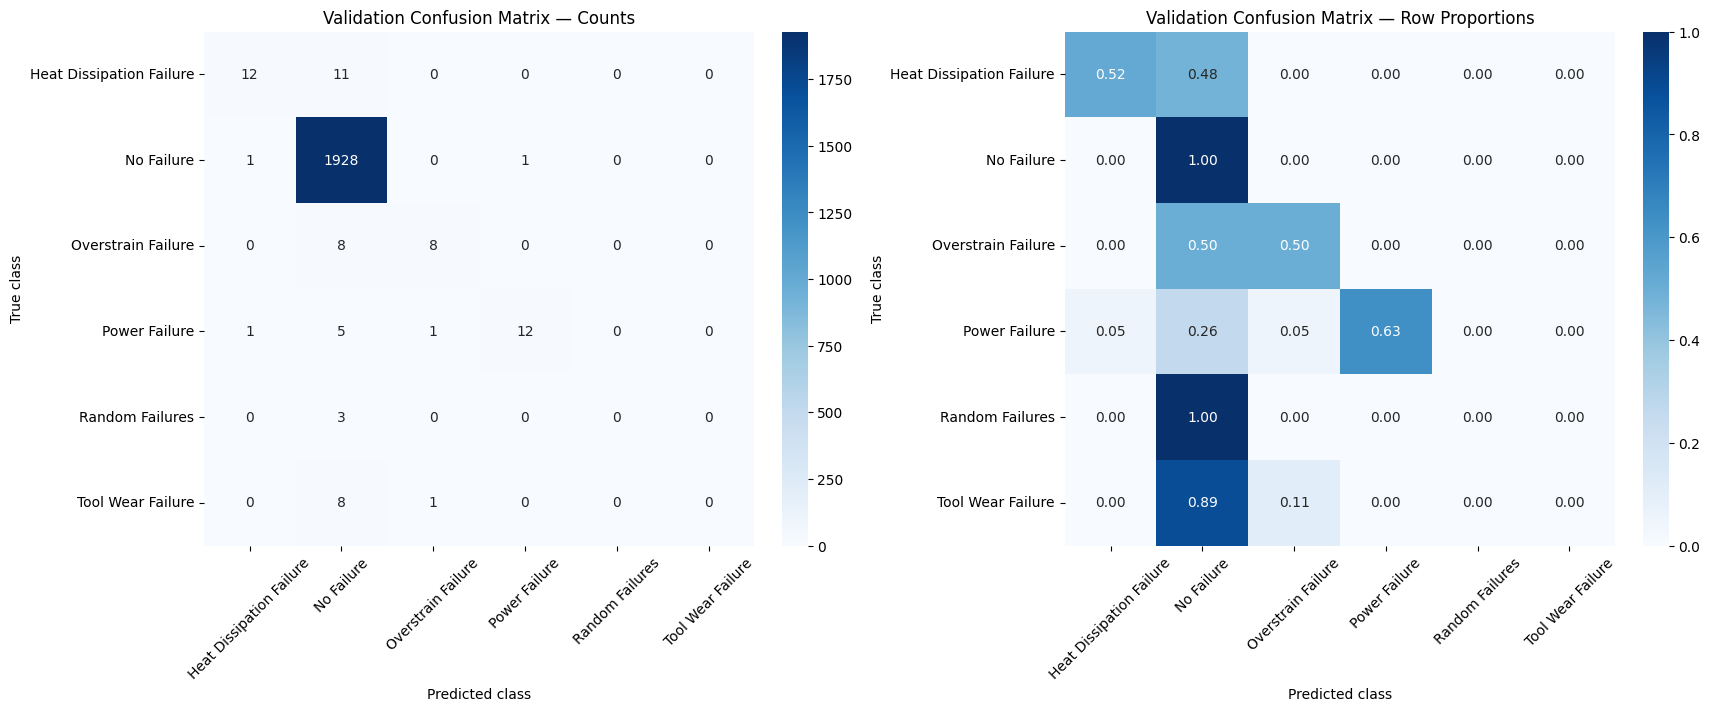

In [21]:
from sklearn.metrics import confusion_matrix

classification_model.eval()

with torch.no_grad():
    baseline_val_predictions = classification_model(
        X_val_device
    ).argmax(dim=1).cpu().numpy()

baseline_validation_report = pd.DataFrame(
    classification_report(
        y_val,
        baseline_val_predictions,
        labels=np.arange(NUM_CLASSES),
        target_names=label_encoder.classes_,
        output_dict=True,
        zero_division=0,
    )
).T

print("BASELINE VALIDATION REPORT")
display(baseline_validation_report.round(4))

cm_counts = confusion_matrix(
    y_val,
    baseline_val_predictions,
    labels=np.arange(NUM_CLASSES),
)

cm_normalized = cm_counts / cm_counts.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(
    1, 2, figsize=(17, 7), constrained_layout=True
)

sns.heatmap(
    cm_counts,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    ax=axes[0],
)
axes[0].set_title("Validation Confusion Matrix — Counts")

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    ax=axes[1],
)
axes[1].set_title("Validation Confusion Matrix — Row Proportions")

for ax in axes:
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", labelrotation=45)
    ax.tick_params(axis="y", labelrotation=0)

fig.savefig(
    PLOT_DIR / "maintenance_baseline_validation_confusion.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

baseline_validation_report.to_csv(
    RESULTS_DIR / "maintenance_baseline_validation_report.csv"
)

pd.DataFrame(
    cm_counts,
    index=label_encoder.classes_,
    columns=label_encoder.classes_,
).rename_axis("true_class").to_csv(
    RESULTS_DIR / "maintenance_baseline_validation_confusion.csv"
)

baseline_prediction_table = pd.DataFrame({
    "UDI": maintenance.loc[validation.index, "UDI"].to_numpy(),
    "true_class": label_encoder.inverse_transform(y_val),
    "predicted_class": label_encoder.inverse_transform(
        baseline_val_predictions
    ),
})

baseline_prediction_table.to_csv(
    RESULTS_DIR / "maintenance_baseline_validation_predictions.csv",
    index=False,
)

In [22]:
baseline_classification_state = {
    key: value.detach().cpu().clone()
    for key, value in classification_model.state_dict().items()
}

final_baseline_epoch = classification_history.iloc[-1]

baseline_classification_metrics = pd.DataFrame([
    {
        "model": "Unresampled MLP",
        "split": split,
        **{
            metric: float(final_baseline_epoch[f"{split}_{metric}"])
            for metric in ["loss", "accuracy", "macro_recall", "macro_f1"]
        },
    }
    for split in ["train", "validation"]
])

np.testing.assert_allclose(
    baseline_classification_metrics.loc[
        baseline_classification_metrics["split"].eq("validation"),
        "macro_f1",
    ].iloc[0],
    baseline_validation_report.loc["macro avg", "f1-score"],
)

baseline_classification_config = {
    "seed": SEED,
    "input_features": feature_names.tolist(),
    "class_names": label_encoder.classes_.tolist(),
    "architecture": [X_train.shape[1], 32, 16, NUM_CLASSES],
    "hidden_activation": "ReLU",
    "output": "Raw logits",
    "loss": "Unweighted CrossEntropyLoss",
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "training_samples": len(y_train),
    "batches_per_epoch": len(train_loader),
    "optimizer_steps": EPOCHS * len(train_loader),
    "resampling": None,
    "selection": "Fixed final epoch",
    "preprocessing_fit_partition": "Original training data",
    "test_evaluated": False,
}

baseline_classification_metrics.to_csv(
    RESULTS_DIR / "maintenance_baseline_metrics.csv",
    index=False,
)

(RESULTS_DIR / "maintenance_baseline_config.json").write_text(
    json.dumps(baseline_classification_config, indent=2),
    encoding="utf-8",
)

display(baseline_classification_metrics.round(6))
print("PASS: baseline metrics agree with the classification report.")
print("Baseline weights preserved in memory.")

,model,split,loss,accuracy,macro_recall,macro_f1
0,Unresampled MLP,train,0.059357,0.979333,0.460983,0.503765
1,Unresampled MLP,validation,0.067498,0.980000,0.442047,0.500755


PASS: baseline metrics agree with the classification report.
Baseline weights preserved in memory.


## 7. Training-only oversampling comparison

Compare random oversampling with the unresampled baseline using the same architecture and 4,700 optimizer updates. Evaluate on original training and validation distributions. Select primarily by validation macro-F1.

In [23]:
from imblearn.over_sampling import RandomOverSampler

validation_snapshot = X_val.copy()
validation_labels_snapshot = y_val.copy()

oversampler = RandomOverSampler(
    sampling_strategy="not majority",
    random_state=SEED,
)

X_train_balanced, y_train_balanced = oversampler.fit_resample(
    X_train, y_train
)

before_counts = np.bincount(y_train, minlength=NUM_CLASSES)
after_counts = np.bincount(y_train_balanced, minlength=NUM_CLASSES)

balancing_summary = pd.DataFrame({
    "failure_type": label_encoder.classes_,
    "original_count": before_counts,
    "balanced_count": after_counts,
    "multiplication_factor": after_counts / before_counts,
})

np.testing.assert_array_equal(X_val, validation_snapshot)
np.testing.assert_array_equal(y_val, validation_labels_snapshot)

assert len(np.unique(after_counts)) == 1
assert len(np.unique(oversampler.sample_indices_)) == len(X_train)
assert np.isfinite(X_train_balanced).all()

display(balancing_summary.round(2))

print("Original training shape:", X_train.shape)
print("Balanced training shape:", X_train_balanced.shape)
print("Validation shape remains:", X_val.shape)
print("PASS: training-only resampling; all original samples retained.")

balancing_summary.to_csv(
    RESULTS_DIR / "maintenance_oversampling_summary.csv",
    index=False,
)

,failure_type,original_count,balanced_count,multiplication_factor
0,Heat Dissipation Failure,67,5792,86.45
1,No Failure,5792,5792,1.00
2,Overstrain Failure,46,5792,125.91
3,Power Failure,57,5792,101.61
4,Random Failures,11,5792,526.55
5,Tool Wear Failure,27,5792,214.52


Original training shape: (6000, 8)
Balanced training shape: (34752, 8)
Validation shape remains: (2000, 8)
PASS: training-only resampling; all original samples retained.


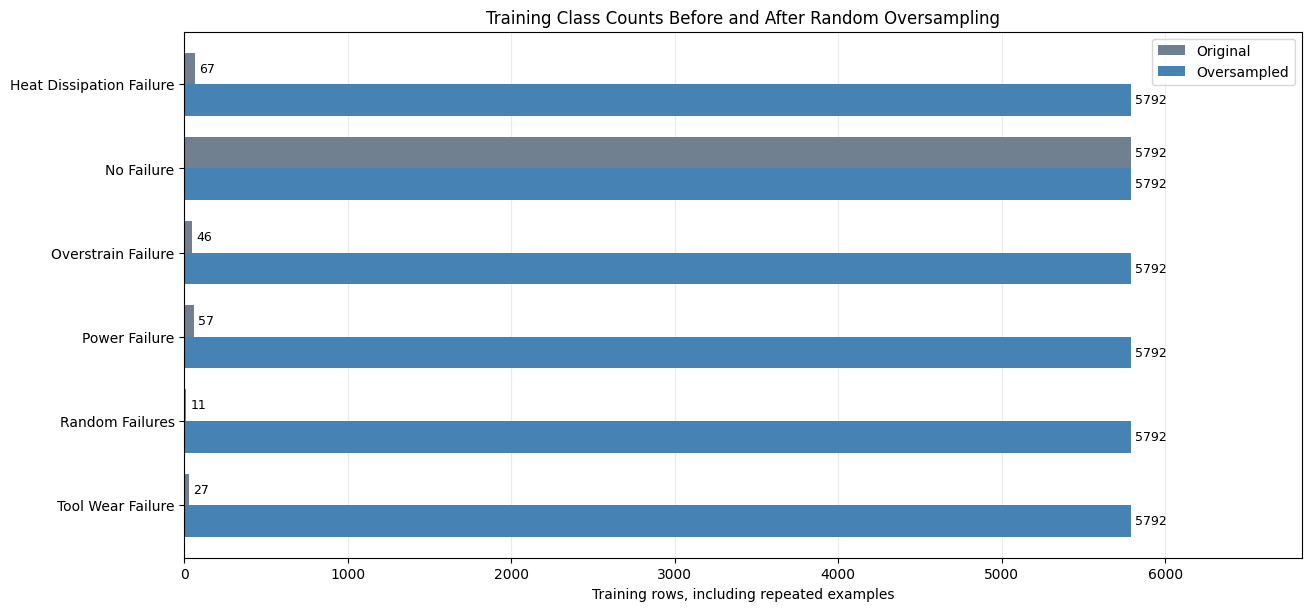

Baseline optimizer updates: 4700
Batches per full oversampled epoch: 543
Updates from 50 full oversampled epochs: 27150


In [25]:
plot_counts = balancing_summary.set_index("failure_type")[
    ["original_count", "balanced_count"]
]

fig, ax = plt.subplots(figsize=(13, 6), constrained_layout=True)

plot_counts.plot.barh(
    ax=ax,
    color=["slategray", "steelblue"],
    width=0.75,
)

ax.invert_yaxis()
ax.set_title("Training Class Counts Before and After Random Oversampling")
ax.set_xlabel("Training rows, including repeated examples")
ax.set_ylabel("")
ax.set_xlim(0, plot_counts.to_numpy().max() * 1.18)
ax.legend(["Original", "Oversampled"])
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=9)

fig.savefig(
    PLOT_DIR / "maintenance_oversampling_class_counts.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

balanced_batches_per_epoch = (
    len(y_train_balanced) + BATCH_SIZE - 1
) // BATCH_SIZE

print("Baseline optimizer updates:",
      baseline_classification_config["optimizer_steps"])
print("Batches per full oversampled epoch:", balanced_batches_per_epoch)
print(
    "Updates from 50 full oversampled epochs:",
    50 * balanced_batches_per_epoch,
)

In [26]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

balanced_model = MaintenanceMLP(
    input_dim=X_train.shape[1],
    num_classes=NUM_CLASSES,
).to(DEVICE)

balanced_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(X_train_balanced.astype(np.float32)),
        torch.from_numpy(y_train_balanced.astype(np.int64)),
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
)

balanced_criterion = nn.CrossEntropyLoss()
balanced_optimizer = torch.optim.Adam(
    balanced_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.0,
)

MAX_UPDATES = int(baseline_classification_config["optimizer_steps"])
EVALUATE_EVERY = int(
    baseline_classification_config["batches_per_epoch"]
)

assert MAX_UPDATES == 4700
assert EVALUATE_EVERY == 94
assert len(balanced_loader) == 543
assert balanced_model is not classification_model

balanced_model.eval()

with torch.no_grad():
    sample_logits = balanced_model(X_train_tensor[:8].to(DEVICE))

assert sample_logits.shape == (8, NUM_CLASSES)
assert torch.isfinite(sample_logits).all()

print("Optimizer-update budget:", MAX_UPDATES)
print("Evaluation interval:", EVALUATE_EVERY)
print("Evaluation points:", MAX_UPDATES // EVALUATE_EVERY)
print("Full oversampled epoch batches:", len(balanced_loader))
print("Updates for 50 full oversampled epochs:", 50 * len(balanced_loader))
print("PASS: fresh model ready; baseline model unchanged.")

Optimizer-update budget: 4700
Evaluation interval: 94
Evaluation points: 50
Full oversampled epoch batches: 543
Updates for 50 full oversampled epochs: 27150
PASS: fresh model ready; baseline model unchanged.


In [27]:
balanced_history_rows = []
updates = 0

while updates < MAX_UPDATES:
    balanced_model.train()

    for X_batch, y_batch in balanced_loader:
        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        balanced_optimizer.zero_grad(set_to_none=True)
        logits = balanced_model(X_batch)
        loss = balanced_criterion(logits, y_batch)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at optimizer update {updates + 1}"
            )

        loss.backward()
        balanced_optimizer.step()
        updates += 1

        if updates % EVALUATE_EVERY == 0:
            balanced_model.eval()

            row = {
                "updates": updates,
                "evaluation_point": updates // EVALUATE_EVERY,
            }

            with torch.no_grad():
                for split, X, y in [
                    ("train", X_train_device, y_train_device),
                    ("validation", X_val_device, y_val_device),
                ]:
                    logits = balanced_model(X)
                    predictions = logits.argmax(dim=1).cpu().numpy()
                    actual = y.cpu().numpy()

                    row[f"{split}_loss"] = balanced_criterion(
                        logits, y
                    ).item()
                    row[f"{split}_accuracy"] = accuracy_score(
                        actual, predictions
                    )
                    row[f"{split}_macro_f1"] = f1_score(
                        actual,
                        predictions,
                        labels=np.arange(NUM_CLASSES),
                        average="macro",
                        zero_division=0,
                    )
                    row[f"{split}_macro_recall"] = (
                        balanced_accuracy_score(actual, predictions)
                    )

            assert all(np.isfinite(value) for value in row.values())
            balanced_history_rows.append(row)

            if row["evaluation_point"] == 1 or row["evaluation_point"] % 10 == 0:
                print(
                    f"Updates {updates:4d}/{MAX_UPDATES} | "
                    f"Validation loss: {row['validation_loss']:.4f} | "
                    f"Accuracy: {row['validation_accuracy']:.4f} | "
                    f"Macro-F1: {row['validation_macro_f1']:.4f} | "
                    f"Macro-recall: {row['validation_macro_recall']:.4f}"
                )

            balanced_model.train()

        if updates >= MAX_UPDATES:
            break

balanced_model.eval()
balanced_history = pd.DataFrame(balanced_history_rows)

assert updates == MAX_UPDATES
assert len(balanced_history) == 50
assert np.isfinite(balanced_history.to_numpy()).all()

balanced_history.to_csv(
    RESULTS_DIR / "maintenance_oversampled_training_history.csv",
    index=False,
)

print("\nPASS: completed exactly 4,700 optimizer updates.")
print("Training metrics use the original 6,000 training rows.")
print("Final-update model retained; no checkpoint selection.")
print("Test set remains unevaluated.")

Updates   94/4700 | Validation loss: 1.7673 | Accuracy: 0.1910 | Macro-F1: 0.1167 | Macro-recall: 0.5546
Updates  940/4700 | Validation loss: 0.6748 | Accuracy: 0.7125 | Macro-F1: 0.3654 | Macro-recall: 0.7107
Updates 1880/4700 | Validation loss: 0.5365 | Accuracy: 0.7875 | Macro-F1: 0.4327 | Macro-recall: 0.7317
Updates 2820/4700 | Validation loss: 0.4361 | Accuracy: 0.8410 | Macro-F1: 0.4502 | Macro-recall: 0.7225
Updates 3760/4700 | Validation loss: 0.3444 | Accuracy: 0.8825 | Macro-F1: 0.4693 | Macro-recall: 0.7297
Updates 4700/4700 | Validation loss: 0.3799 | Accuracy: 0.8785 | Macro-F1: 0.4827 | Macro-recall: 0.7290

PASS: completed exactly 4,700 optimizer updates.
Training metrics use the original 6,000 training rows.
Final-update model retained; no checkpoint selection.
Test set remains unevaluated.


OVERSAMPLED MODEL: VALIDATION REPORT


,precision,recall,f1-score,support
Heat Dissipation Failure,0.4894,1.0000,0.6571,23.0000
No Failure,0.9971,0.8793,0.9345,1930.0000
Overstrain Failure,0.3684,0.8750,0.5185,16.0000
Power Failure,0.5517,0.8421,0.6667,19.0000
Random Failures,0.0000,0.0000,0.0000,3.0000
Tool Wear Failure,0.0648,0.7778,0.1197,9.0000
accuracy,0.8785,0.8785,0.8785,0.8785
macro avg,0.4119,0.7290,0.4827,2000.0000
weighted avg,0.9763,0.8785,0.9203,2000.0000


PER-CLASS COMPARISON


,baseline_recall,oversampled_recall,baseline_f1,oversampled_f1,support
Heat Dissipation Failure,0.5217,1.0000,0.6486,0.6571,23.0
No Failure,0.9990,0.8793,0.9905,0.9345,1930.0
Overstrain Failure,0.5000,0.8750,0.6154,0.5185,16.0
Power Failure,0.6316,0.8421,0.7500,0.6667,19.0
Random Failures,0.0000,0.0000,0.0000,0.0000,3.0
Tool Wear Failure,0.0000,0.7778,0.0000,0.1197,9.0


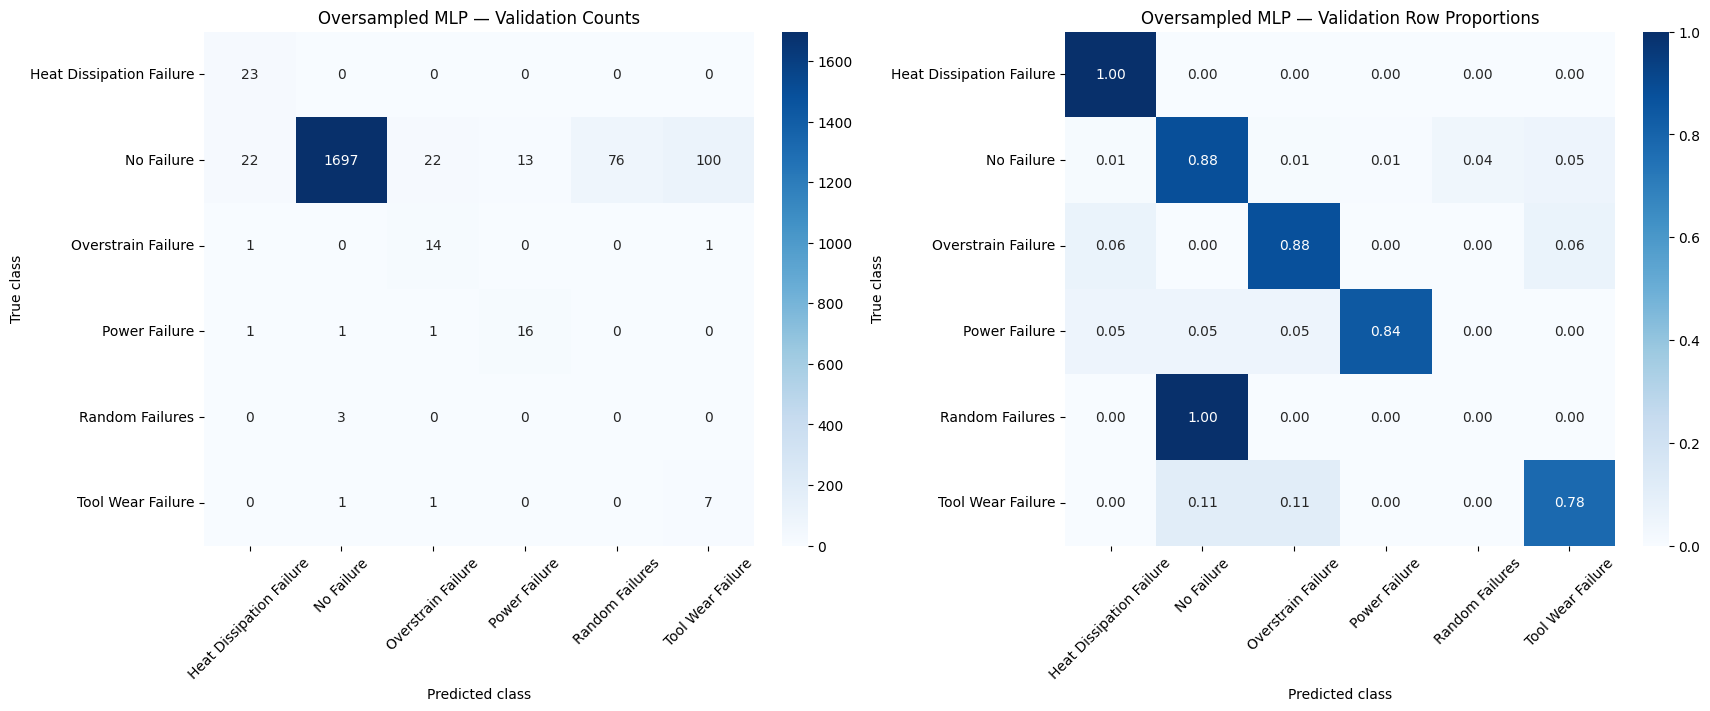

In [28]:
balanced_model.eval()

with torch.no_grad():
    balanced_val_predictions = balanced_model(
        X_val_device
    ).argmax(dim=1).cpu().numpy()

balanced_validation_report = pd.DataFrame(
    classification_report(
        y_val,
        balanced_val_predictions,
        labels=np.arange(NUM_CLASSES),
        target_names=label_encoder.classes_,
        output_dict=True,
        zero_division=0,
    )
).T

print("OVERSAMPLED MODEL: VALIDATION REPORT")
display(balanced_validation_report.round(4))

per_class_comparison = pd.DataFrame({
    "baseline_recall": baseline_validation_report.loc[
        label_encoder.classes_, "recall"
    ],
    "oversampled_recall": balanced_validation_report.loc[
        label_encoder.classes_, "recall"
    ],
    "baseline_f1": baseline_validation_report.loc[
        label_encoder.classes_, "f1-score"
    ],
    "oversampled_f1": balanced_validation_report.loc[
        label_encoder.classes_, "f1-score"
    ],
    "support": balanced_validation_report.loc[
        label_encoder.classes_, "support"
    ],
})

print("PER-CLASS COMPARISON")
display(per_class_comparison.round(4))

balanced_cm = confusion_matrix(
    y_val,
    balanced_val_predictions,
    labels=np.arange(NUM_CLASSES),
)

balanced_cm_normalized = (
    balanced_cm / balanced_cm.sum(axis=1, keepdims=True)
)

fig, axes = plt.subplots(
    1, 2, figsize=(17, 7), constrained_layout=True
)

for ax, values, fmt, title in [
    (axes[0], balanced_cm, "d", "Oversampled MLP — Validation Counts"),
    (
        axes[1],
        balanced_cm_normalized,
        ".2f",
        "Oversampled MLP — Validation Row Proportions",
    ),
]:
    sns.heatmap(
        values,
        annot=True,
        fmt=fmt,
        cmap="Blues",
        vmin=0,
        vmax=1 if fmt == ".2f" else None,
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", labelrotation=45)
    ax.tick_params(axis="y", labelrotation=0)

fig.savefig(
    PLOT_DIR / "maintenance_oversampled_validation_confusion.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

balanced_validation_report.to_csv(
    RESULTS_DIR / "maintenance_oversampled_validation_report.csv"
)
per_class_comparison.to_csv(
    RESULTS_DIR / "maintenance_oversampling_per_class_comparison.csv"
)
pd.DataFrame(
    balanced_cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_,
).rename_axis("true_class").to_csv(
    RESULTS_DIR / "maintenance_oversampled_validation_confusion.csv"
)

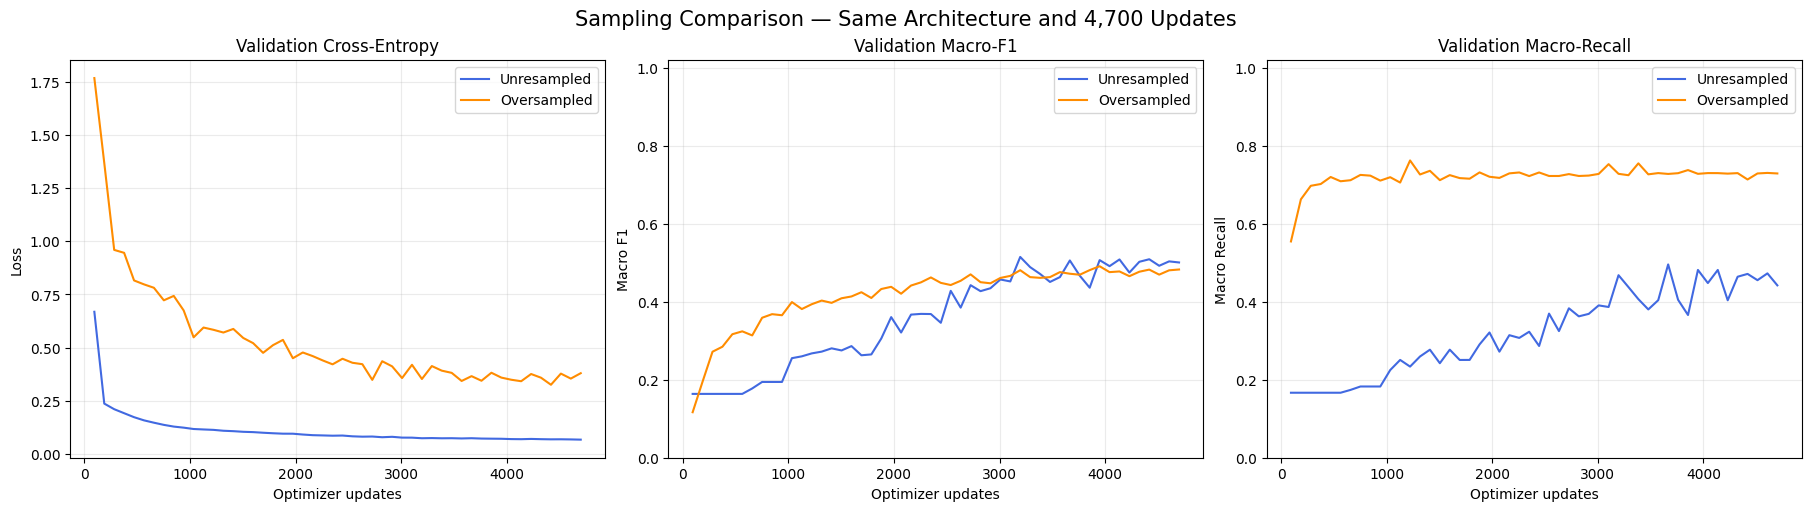

In [30]:
baseline_updates = (
    classification_history["epoch"]
    * baseline_classification_config["batches_per_epoch"]
)

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5), constrained_layout=True
)

for ax, metric, title in zip(
    axes,
    ["loss", "macro_f1", "macro_recall"],
    ["Validation Cross-Entropy", "Validation Macro-F1", "Validation Macro-Recall"],
):
    ax.plot(
        baseline_updates,
        classification_history[f"validation_{metric}"],
        label="Unresampled",
        color="royalblue",
    )
    ax.plot(
        balanced_history["updates"],
        balanced_history[f"validation_{metric}"],
        label="Oversampled",
        color="darkorange",
    )

    ax.set_title(title)
    ax.set_xlabel("Optimizer updates")
    ax.set_ylabel(metric.replace("_", " ").title())
    ax.grid(alpha=0.25)
    ax.legend()

    if metric != "loss":
        ax.set_ylim(0, 1.02)

fig.suptitle(
    "Sampling Comparison — Same Architecture and 4,700 Updates",
    fontsize=15,
)

fig.savefig(
    PLOT_DIR / "maintenance_sampling_learning_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

In [31]:
final_balanced = balanced_history.iloc[-1]

oversampled_metrics = pd.DataFrame([
    {
        "model": "Oversampled MLP",
        "split": split,
        **{
            metric: float(final_balanced[f"{split}_{metric}"])
            for metric in ["loss", "accuracy", "macro_recall", "macro_f1"]
        },
    }
    for split in ["train", "validation"]
])

sampling_comparison = pd.concat(
    [baseline_classification_metrics, oversampled_metrics],
    ignore_index=True,
)

np.testing.assert_allclose(
    final_balanced["validation_macro_f1"],
    balanced_validation_report.loc["macro avg", "f1-score"],
)

balanced_prediction_table = pd.DataFrame({
    "UDI": maintenance.loc[validation.index, "UDI"].to_numpy(),
    "true_class": label_encoder.inverse_transform(y_val),
    "predicted_class": label_encoder.inverse_transform(
        balanced_val_predictions
    ),
})

oversampling_config = {
    "seed": SEED,
    "method": "RandomOverSampler",
    "sampling_strategy": "not majority",
    "original_training_samples": len(y_train),
    "resampled_training_samples": len(y_train_balanced),
    "class_counts": balancing_summary.to_dict(orient="records"),
    "architecture": [X_train.shape[1], 32, 16, NUM_CLASSES],
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "optimizer_updates": MAX_UPDATES,
    "evaluation_interval_updates": EVALUATE_EVERY,
    "selection": "Fixed final update; no checkpoint selection",
    "preprocessing_fit_partition": "Original training data",
    "training_metrics_partition": "Original unresampled training data",
    "validation_resampled": False,
    "test_evaluated": False,
    "primary_comparison_metric": "Validation macro-F1",
    "budget_note": (
        "Matched optimizer updates; final-batch sizes differ between loaders."
    ),
    "cv_policy": (
        "Fit preprocessing and resampling inside each training fold; "
        "never pass these globally oversampled arrays into cross-validation."
    ),
}

sampling_comparison.to_csv(
    RESULTS_DIR / "maintenance_sampling_comparison.csv",
    index=False,
)

balanced_prediction_table.to_csv(
    RESULTS_DIR / "maintenance_oversampled_validation_predictions.csv",
    index=False,
)

(RESULTS_DIR / "maintenance_oversampling_config.json").write_text(
    json.dumps(oversampling_config, indent=2),
    encoding="utf-8",
)

balanced_classification_state = {
    key: value.detach().cpu().clone()
    for key, value in balanced_model.state_dict().items()
}

display(sampling_comparison.round(6))

print("PASS: comparison, predictions, and configuration saved.")
print("Oversampled model weights preserved in memory.")
print("Test set remains unevaluated.")

,model,split,loss,accuracy,macro_recall,macro_f1
0,Unresampled MLP,train,0.059357,0.979333,0.460983,0.503765
1,Unresampled MLP,validation,0.067498,0.980000,0.442047,0.500755
2,Oversampled MLP,train,0.345770,0.880000,0.976823,0.509334
3,Oversampled MLP,validation,0.379919,0.878500,0.729026,0.482743


PASS: comparison, predictions, and configuration saved.
Oversampled model weights preserved in memory.
Test set remains unevaluated.


### Training-only oversampling comparison

RandomOverSampler increased each training class to 5,792 rows,
producing 34,752 training rows. All original samples were retained.
Oversampling repeated existing observations rather than generating
new information; Random Failures still had only 11 distinct originals.

Preprocessing was fitted on the original training data. Validation
and test data were not resampled.

Both MLPs used architecture 8–32–16–6, the same initialization seed,
Adam with learning rate 0.001, batch size 64, and 4,700 optimizer
updates. Final-batch sizes differed between loaders. No early stopping
or checkpoint selection was used.

All training metrics were computed on the original 6,000 training rows.

| Model | Validation accuracy | Macro-recall | Macro-F1 |
|---|---:|---:|---:|
| Unresampled MLP | 0.980000 | 0.442047 | 0.500755 |
| Oversampled MLP | 0.878500 | 0.729026 | 0.482743 |

Oversampling improved recall for Heat Dissipation, Overstrain, Power,
and Tool Wear failures. However, it increased false alarms: 233 of
1,930 No Failure examples were classified as failures, versus two
for the unresampled model.

Tool Wear recall improved from 0/9 to 7/9, but precision was only
6.48%. Random Failures remained undetected on validation (0/3).

Oversampled training macro-recall was 0.9768 compared with 0.7290
on validation, indicating a class-level generalization gap.
Minority-class estimates remain uncertain because supports are small.

Full oversampling did not improve the primary selection metric,
validation macro-F1. The unresampled model remains preferred under
this criterion for the current comparison.

Future cross-validation must fit preprocessing and any resampling
within each training fold. Globally oversampled arrays must not be
used as the input to cross-validation.

The test set remains unevaluated.

## 8. GridSearchCV with skorch and stratified folds

TODO: implement and document this section.


## 9. Controlled regularization comparisons

TODO: implement and document this section.


## 10. Frozen-model train/test curves and final metrics

TODO: implement and document this section.


## 11. Interpretation and exported results

TODO: implement and document this section.
